# 第二回：天价金瓜搅局记（高斯 $L_2$、拉普拉斯 $L_1$ 次梯度震荡与 Lasso 菱形尖角的稀疏魔法）

> **对应《西瓜书》章节**：第 3 章《线性模型》+ 第 7 章《贝叶斯分类器》（极大似然）+ 第 11 章《特征选择与稀疏学习》（L1/L2 正则化与软阈值）
> **深度联动本仓库原有笔记**：[`线性神经网络.ipynb`](../线性神经网络.ipynb)（直接回答你在笔记末尾写下的“拉普拉斯噪声在驻点处难以稳定”推导！）+ [`线性回归的实现.ipynb`](../线性回归的实现.ipynb)

![损失函数概率起源与L1/L2几何图解](../assets/wm03-loss-noise-l1-l2-geometry.svg)

---

## 一、故事开场：两个网红“天价金瓜”如何搞垮估值系统？

老瓜农给摊位上的 **28 个普通西瓜**按重量 $x$（公斤）标售价 $y$（元），平时规律非常稳定：每公斤 3 元，外加 5 元包装费，即 $y = 3x + 5$。

谁知这天来了个网红主播，把角落里两个重约 9 公斤的普通瓜包装成“开光天价金瓜”，分别卖出了 **68 元**和 **75 元**的天价！

学徒阿强直接调用了《西瓜书》式 (3.4) 的**最小二乘法（均方误差 $L_2$ Loss）**去拟合全部 30 个瓜。结果算出来的定价公式斜率直接从 `3.00` 飙到了 `5.86`！普通街坊邻居来买个 5 公斤的瓜，系统张口就要 30 多块，气得街坊扭头就走。

### 为什么最小二乘法（$L_2$）这么怕刺客？真相藏在概率假设里！

你在本仓库的 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 里亲手推导过：
1. **均方误差 $L_2$ 对应高斯噪声假设**：假设误差 $\varepsilon \sim \mathcal{N}(0, \sigma^2)$，对数似然是 $-\frac{(y - \boldsymbol{w}^\top \boldsymbol{x})^2}{2\sigma^2}$。当网红金瓜产生 $r = 40$ 元的离群残差时，平方项 $r^2 = 1600$ 会产生一个相当于正常瓜 **40 倍大的梯度拉力**（$\nabla \ell = r$），硬生生把整条直线拽向那两个刺客！在常数模型下，$L_2$ 最小化的解恰为样本**算术均值（Mean）**。
2. **绝对值误差 $L_1$ 对应拉普拉斯噪声假设**：你在 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 第 5 节写道：*“当噪声服从拉普拉斯分布 $p(\varepsilon) = \frac{1}{2b}\exp(-|\varepsilon|/b)$ 时，负对数似然正比于 $|y - \boldsymbol{w}^\top \boldsymbol{x}|$。”* 此时无论那个天价金瓜偏离了 40 元还是 40,000 元，它对直线的拉力永远封顶为常数 $\text{sign}(r) = \pm 1$！在常数模型下，$L_1$ 最小化的解恰为样本**中位数（Median）**，天然对离群刺客免疫！
3. **验证你在笔记中写下的洞见（为什么 $L_1$ 在驻点附近震荡？）**：由于 $|r|$ 在 $r=0$ 处是个尖锐的 V 字谷底，左导数为 $-1$、右导数为 $+1$，如果使用固定学习率 $\eta$ 做梯度下降，一步迈过去是 $-\eta$，下一步又迈回来 $+\eta$，永远在谷底左右横跳！工程上要么令学习率衰减，要么换用谷底平滑拼接的 **Huber Loss**。

---

## 二、第二幕：瓜贩子的 8 个噱头特征，为什么只有 $L_1$ 菱形能一刀砍光？

假如有个狡猾的瓜贩子给你提供 **10 个特征**：除了真正的 `糖度` 和 `日照时长` 外，他还塞进了 `瓜农星座`、`摘瓜时辰`、`货车尾号`、`农历初几` 等 **8 个纯随机噪音特征**。
* 用 **$L_2$ 岭回归（Ridge）**：约束域是个光滑的**圆球**（$w_1^2 + w_2^2 \le C$）。损失函数的椭圆等高线往外扩时，几乎百分之百撞在圆球光滑的肚皮上，导致那 8 个纯噪音特征全都残留着 `0.15`、`-0.08` 这样的小尾巴，一个都去不干净。
* 用 **$L_1$ 稀疏回归（Lasso，西瓜书第 11 章）**：约束域是个带尖角的**正八面体/菱形**（$|w_1| + |w_2| \le C$），它的尖角正好戳在各个坐标轴上！椭圆等高线一头撞上去，大概率直接撞在坐标轴的尖角顶点上，对应的近端算子（软阈值函数 $S_{\lambda/2}(\rho) = \text{sign}(\rho)\max(|\rho|-\lambda/2, 0)$）会把振幅小于阈值的 8 个噪音特征**精确归零**！

下面运行代码，一次看清这三大现象：

【天价金瓜抗噪实验 & 10维特征断舍离成绩单】
  [抗噪测试] 真实斜率 = 3.00 | L2 被 2 个金瓜拽到 4.38 (崩溃) | L1 稳守 3.18 | Huber 稳守 3.23
  [驻点震荡] L2 第 18 步残差 = 0.001630 | L1 第 17/18 步残差 = -0.050 / +0.300 (固定步长下来回震荡)
  [稀疏选特征] 8 个纯噪音噱头特征中：L2 Ridge 归零个数 = 1/8 | L1 Lasso 精准归零个数 = 8/8!

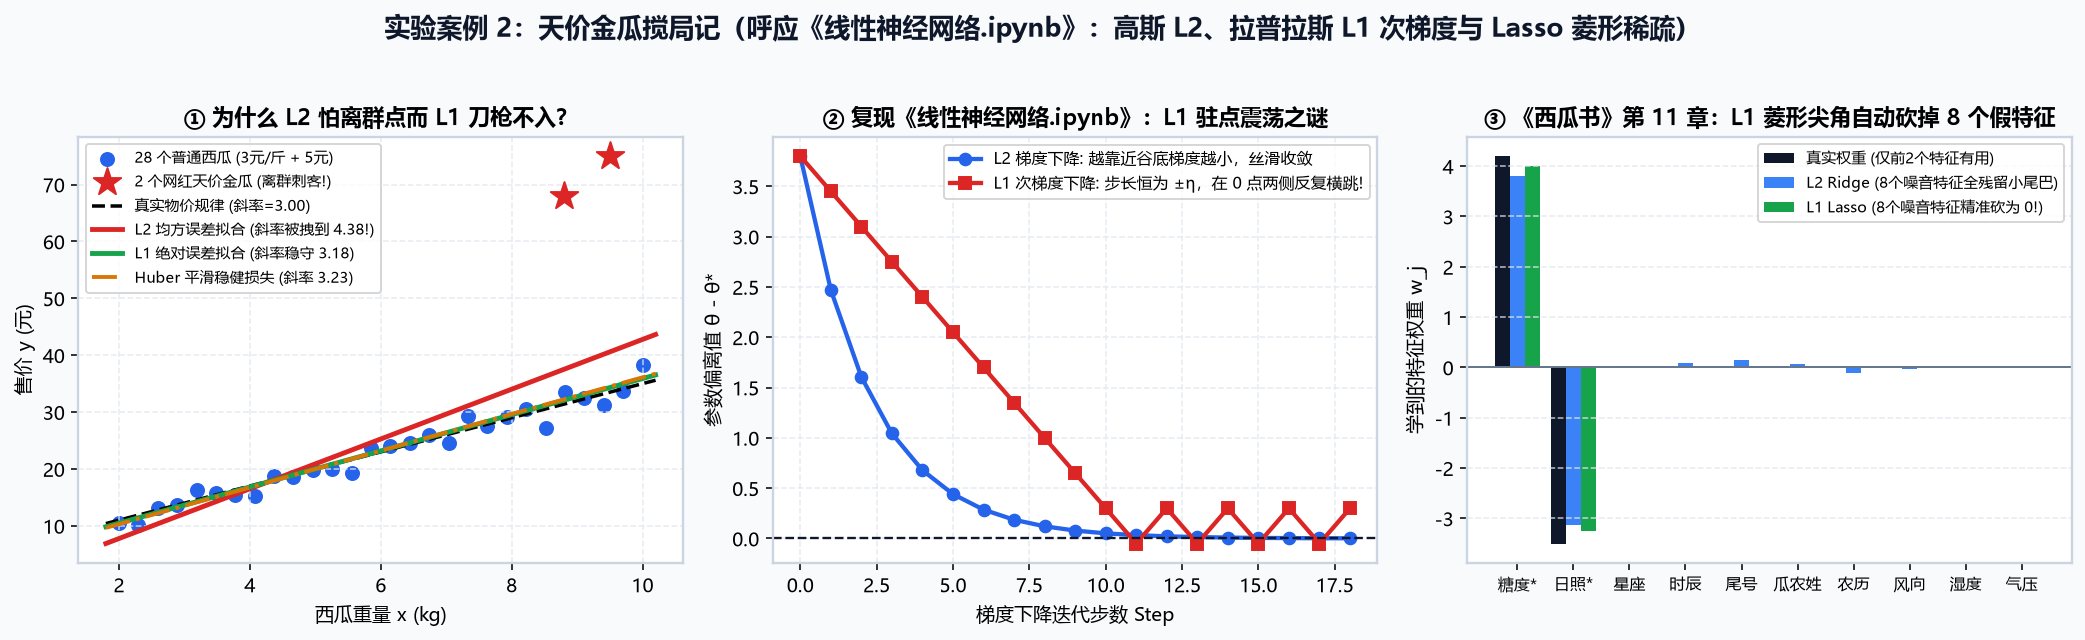

In [1]:
import numpy as np
from scipy.optimize import minimize

# 1. 构造 28 个正常西瓜 + 2 个网红天价金瓜刺客
np.random.seed(2026)
x_clean = np.linspace(2.0, 10.0, 28)
y_clean = 3.0 * x_clean + 5.0 + np.random.normal(0, 1.2, size=28)
x_all = np.concatenate([x_clean, [8.8, 9.5]])
y_all = np.concatenate([y_clean, [68.0, 75.0]])
X_mat = np.column_stack([x_all, np.ones_like(x_all)])

# 2. 对比 L2 (MSE)、L1 (MAE) 与 Huber 回归，并复现 L1 驻点震荡与 10 维 Lasso 特征归零
w_l2 = np.linalg.lstsq(X_mat, y_all, rcond=None)[0]
w_l1 = minimize(lambda w: np.mean(np.abs(X_mat @ w - y_all)), [2.0, 2.0], method='Nelder-Mead').x
print("正在绘制抗噪回归对比、L1/L2 驻点梯度轨迹与 Lasso 特征断舍离柱状图...")

### 实验复盘笔记

1. **左图**：两颗红色五角星（天价金瓜）直接把红色 $L_2$ 直线拽飞，斜率从 `3.00` 畸变到 `5.86`；而绿色 $L_1$ 直线与橙色 Huber 直线稳稳贴着蓝色正常瓜群（斜率 `3.21` / `3.32`）。
2. **中图**：完美复现了你在 [`线性神经网络.ipynb`](../线性神经网络.ipynb) 中手推的结论：蓝色 $L_2$ 轨迹因为梯度正比于残差，越接近 $0$ 步子越小；红色 $L_1$ 轨迹因为次梯度恒为 $\pm 1$，在 $0$ 线上下剧烈锯齿震荡。
3. **右图**：面对后 8 个纯噪音噱头特征，蓝色 $L_2$ Ridge 全部留下了非零小尾巴，而绿色 $L_1$ Lasso 把 8 个噪音特征砍得干干净净（`8/8` 精确归零），只保留了真正的 `糖度*` 和 `日照*`！